In [13]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader
import os
import matplotlib.pyplot as plt

# Define the PyramidFeatures class
class PyramidFeatures(nn.Module):
    def __init__(self, C3_size, C4_size, C5_size, feature_size=256):
        super(PyramidFeatures, self).__init__()
        self.P5_1 = nn.Conv2d(C5_size, feature_size, kernel_size=1, stride=1, padding=0)
        self.P5_upsampled = nn.Upsample(scale_factor=2, mode='nearest')
        self.P5_2 = nn.Conv2d(feature_size, feature_size, kernel_size=3, stride=1, padding=1)
        self.P4_1 = nn.Conv2d(C4_size, feature_size, kernel_size=1, stride=1, padding=0)
        self.P4_upsampled = nn.Upsample(scale_factor=2, mode='nearest')
        self.P4_2 = nn.Conv2d(feature_size, feature_size, kernel_size=3, stride=1, padding=1)
        self.P3_1 = nn.Conv2d(C3_size, feature_size, kernel_size=1, stride=1, padding=0)
        self.P3_2 = nn.Conv2d(feature_size, feature_size, kernel_size=3, stride=1, padding=1)
        self.P6 = nn.Conv2d(C5_size, feature_size, kernel_size=3, stride=2, padding=1)
        self.P7_1 = nn.ReLU()
        self.P7_2 = nn.Conv2d(feature_size, feature_size, kernel_size=3, stride=2, padding=1)

    def forward(self, inputs):
        C3, C4, C5 = inputs
        P5_x = self.P5_1(C5)
        P5_upsampled_x = self.P5_upsampled(P5_x)
        P5_x = self.P5_2(P5_x)
        P4_x = self.P4_1(C4)
        P4_x = P5_upsampled_x + P4_x
        P4_upsampled_x = self.P4_upsampled(P4_x)
        P4_x = self.P4_2(P4_x)
        P3_x = self.P3_1(C3)
        P3_x = P3_x + P4_upsampled_x
        P3_x = self.P3_2(P3_x)
        P6_x = self.P6(C5)
        P7_x = self.P7_1(P6_x)
        P7_x = self.P7_2(P7_x)
        return [P3_x, P4_x, P5_x, P6_x, P7_x]

# Define the BlockIR class
class BlockIR(nn.Module):
    def __init__(self, inplanes, planes, stride, dim_match):
        super(BlockIR, self).__init__()
        self.bn1 = nn.BatchNorm2d(inplanes)
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)
        self.prelu1 = nn.PReLU(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn3 = nn.BatchNorm2d(planes)

        if dim_match:
            self.downsample = None
        else:
            self.downsample = nn.Sequential(
                nn.Conv2d(inplanes, planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes),
            )

    def forward(self, x):
        residual = x
        out = self.bn1(x)
        out = self.conv1(out)
        out = self.bn2(out)
        out = self.prelu1(out)
        out = self.conv2(out)
        out = self.bn3(out)
        if self.downsample is not None:
            residual = self.downsample(x)
        out += residual
        return out

# Define the base LResNet_Occ_FC class
class LResNet_Occ_FC(nn.Module):
    def __init__(self, block, layers, filter_list, is_gray=False):
        self.inplanes = 64
        super(LResNet_Occ_FC, self).__init__()
        if is_gray:
            self.conv1 = nn.Conv2d(1, filter_list[0], kernel_size=3, stride=1, padding=1, bias=False)  # gray
        else:
            self.conv1 = nn.Conv2d(3, filter_list[0], kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(filter_list[0])
        self.prelu1 = nn.PReLU(filter_list[0])
        self.layer1 = self._make_layer(block, filter_list[0], filter_list[1], layers[0], stride=2)
        self.layer2 = self._make_layer(block, filter_list[1], filter_list[2], layers[1], stride=2)
        self.layer3 = self._make_layer(block, filter_list[2], filter_list[3], layers[2], stride=2)
        self.layer4 = self._make_layer(block, filter_list[3], filter_list[4], layers[3], stride=2)

        self.mask = nn.Sequential(
            nn.BatchNorm1d(64 * 7 * 6),
            nn.Linear(64 * 7 * 6, 512),
            nn.BatchNorm1d(512),  # fix gamma ???
            nn.Sigmoid(),
        )
        self.fpn = PyramidFeatures(filter_list[2], filter_list[3], filter_list[4])

        self.reduces = nn.Sequential(
            nn.Conv2d(256, 256, kernel_size=3, stride=2, padding=1, bias=False),
            nn.PReLU(256),
            nn.BatchNorm2d(256),
            nn.Conv2d(256, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.PReLU(64),
            nn.BatchNorm2d(64)
        )

        self.regress = nn.Sequential(
            nn.BatchNorm1d(512),
            nn.Dropout(p=0.5),  # No drop for triplet dic
            nn.Linear(512, filter_list[5], bias=False),
            nn.BatchNorm1d(filter_list[5]),
        )

        self.fc = nn.Sequential(
            nn.BatchNorm1d(filter_list[4] * 7 * 6),
            nn.Dropout(p=0.5),  # No drop for triplet dic
            nn.Linear(filter_list[4] * 7 * 6, 512),
            nn.BatchNorm1d(512),  # fix gamma ???
        )

        # Weight initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)
            elif isinstance(m, nn.BatchNorm2d) or isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def _make_layer(self, block, inplanes, planes, blocks, stride):
        layers = []
        layers.append(block(inplanes, planes, stride, False))
        for i in range(1, blocks):
            layers.append(block(planes, planes, stride=1, dim_match=True))
        return nn.Sequential(*layers)

    def forward(self, x, mask=None):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.prelu1(x)
        x1 = self.layer1(x)
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        fmap = self.layer4(x3)

        # generate mask
        if not isinstance(mask, torch.Tensor):
            features = self.fpn([x2, x3, fmap])
            fmap_reduce = self.reduces(features[0])
            mask = self.mask(fmap_reduce.view(fmap_reduce.size(0), -1))

        # regress
        vec = self.regress(mask)

        fc = self.fc(fmap.view(fmap.size(0), -1))

        fc_mask = fc * mask

        return fc_mask, mask, vec, fc

    def save(self, file_path):
        with open(file_path, 'wb') as f:
            torch.save(self.state_dict(), f)

# Custom model class extending the provided model
class CustomLResNet_Occ_FC(LResNet_Occ_FC):
    def __init__(self, num_classes, block, layers, filter_list, is_gray=False):
        super(CustomLResNet_Occ_FC, self).__init__(block, layers, filter_list, is_gray)
        # Replace the final fully connected layer
        self.fc_out = nn.Linear(512, num_classes)

    def forward(self, x, mask=None):
        # Use the forward method from the parent class
        fc_mask, mask, vec, fc = super(CustomLResNet_Occ_FC, self).forward(x, mask)
        # Apply the new output layer
        out = self.fc_out(fc_mask)
        return out, fc_mask, mask, vec, fc

Epoch [1/28], Train Loss: 5.3456, Train Accuracy: 0.0409
Validation Loss: 4.7533, Validation Accuracy: 0.0860
Epoch [2/28], Train Loss: 4.3453, Train Accuracy: 0.1360
Validation Loss: 4.0510, Validation Accuracy: 0.1725
Epoch [3/28], Train Loss: 3.6205, Train Accuracy: 0.2469
Validation Loss: 3.3784, Validation Accuracy: 0.2996
Epoch [4/28], Train Loss: 2.9908, Train Accuracy: 0.3642
Validation Loss: 2.8382, Validation Accuracy: 0.3885
Epoch [5/28], Train Loss: 2.5086, Train Accuracy: 0.4557
Validation Loss: 2.4192, Validation Accuracy: 0.4698
Epoch [6/28], Train Loss: 2.1268, Train Accuracy: 0.5324
Validation Loss: 2.1849, Validation Accuracy: 0.5209
Epoch [7/28], Train Loss: 1.8443, Train Accuracy: 0.5910
Validation Loss: 1.8572, Validation Accuracy: 0.5839
Epoch [8/28], Train Loss: 1.5915, Train Accuracy: 0.6418
Validation Loss: 1.6948, Validation Accuracy: 0.6267
Epoch [9/28], Train Loss: 1.3997, Train Accuracy: 0.6854
Validation Loss: 1.5574, Validation Accuracy: 0.6529
Epoch [10/

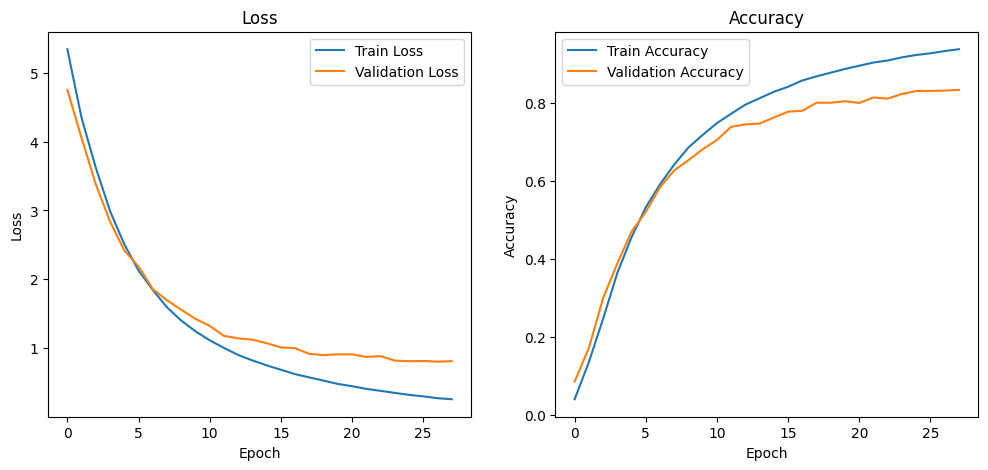

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader, random_split
import os
import matplotlib.pyplot as plt

# Configuration
num_classes = 465  # Set this to the number of classes in your dataset
batch_size = 32
num_epochs = 28
learning_rate = 1e-4
data_dir = r"E:\FYP\newwork\mydata\AFDB_face_dataset"  # Replace with your dataset directory
save_model_path = 'from_model_28.pth'
validation_split = 0.2  # 20% for validation

# Data transformations
transform = transforms.Compose([
    transforms.RandomResizedCrop((112, 96), scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
])

# Load the entire dataset from a single directory
dataset = datasets.ImageFolder(root=data_dir, transform=transform)

# Split dataset into training and validation sets
dataset_size = len(dataset)
val_size = int(dataset_size * validation_split)
train_size = dataset_size - val_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4)

# Initialize the model
model = CustomLResNet_Occ_FC(num_classes=num_classes, block=BlockIR, layers=[3, 4, 14, 3], filter_list=[64, 64, 128, 256, 512, 101])

# Move the model to the appropriate device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Early stopping parameters
best_val_loss = float('inf')
early_stop_count = 0
early_stop_patience = 5

# Lists to store training and validation loss and accuracy
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

# Training and validation loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs, *_ = model(inputs)  # Only take the first output (fc_mask) for classification
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
    
    train_loss = running_loss / len(train_loader)
    train_acc = correct_train / total_train
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    
    print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc:.4f}')
    
    # Validation loop
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs, *_ = model(inputs)  # Only take the first output for evaluation
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = correct_val / total_val
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)
    
    print(f'Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.4f}')

    # Early stopping check
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        early_stop_count = 0
        torch.save(model.state_dict(), save_model_path)  # Save the best model
    else:
        early_stop_count += 1
        if early_stop_count >= early_stop_patience:
            print('Early stopping triggered.')
            break

print('Training completed.')

# Plotting training and validation loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Plotting training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()
